In [1]:
import os
import sys

# Move from notebooks folder to project root
PROJECT_ROOT = os.path.abspath("..")

# Add project root to Python's import path
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)
print("src folder exists:", os.path.isdir(os.path.join(PROJECT_ROOT, "src")))

Project root: /Users/mubhinbasnet/Desktop/student-dropout-prediction
src folder exists: True


In [2]:
from pathlib import Path

project_root = Path.cwd().parent

print("Project root:", project_root)
print("Dataset exists:", (project_root / "data/raw/data.csv").exists())
print("Dataset path:", project_root / "data/raw/data.csv")

Project root: /Users/mubhinbasnet/Desktop/student-dropout-prediction
Dataset exists: True
Dataset path: /Users/mubhinbasnet/Desktop/student-dropout-prediction/data/raw/data.csv


In [3]:
import importlib
import src.data

importlib.reload(src.data)

from src.data import create_data_split

X_train, X_test, y_train, y_test = create_data_split()

Dataset successfully prepared
----------------------------------------
Total records: 3630
Features: 24

Training records: 2904
Testing records: 726

Training target distribution:
target
0    0.608
1    0.392
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.609
1    0.391
Name: proportion, dtype: float64


In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

from src.data import create_data_split
from src.features import build_preprocessor
from src.config import RANDOM_STATE


In [5]:
# Load the original training and test data
X_train, X_test, y_train, y_test = create_data_split()

# Divide training data into training and validation sets

X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Model training records:", len(X_train_model))
print("Validation records:", len(X_val))
print("Final test records:", len(X_test))


Dataset successfully prepared
----------------------------------------
Total records: 3630
Features: 24

Training records: 2904
Testing records: 726

Training target distribution:
target
0    0.608
1    0.392
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.609
1    0.391
Name: proportion, dtype: float64
Model training records: 2323
Validation records: 581
Final test records: 726


In [6]:

def evaluate_model(model, X, y, model_name):
    """
    Evaluate a classification model.
    """

    predictions = model.predict(X)

    probabilities = model.predict_proba(X)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities)
    }

    return results


# Model 1 — Dummy Classifier (baseline)

In [7]:

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train_model,
    y_train_model
)

dummy_results = evaluate_model(
    dummy_model,
    X_val,
    y_val,
    "Dummy Classifier"
)

print(dummy_results)


{'Model': 'Dummy Classifier', 'Accuracy': 0.6092943201376936, 'Precision': 0.0, 'Recall': 0.0, 'F1 Score': 0.0, 'ROC-AUC': 0.5, 'PR-AUC': 0.39070567986230637}


# A simple business rule

In [8]:

def business_rule_predict(data):

    predictions = (
        (data["Debtor"] == 1) |
        (data["Tuition fees up to date"] == 0)
    )

    return predictions.astype(int)


rule_predictions = business_rule_predict(X_val)

rule_results = {
    "Model": "Business Rule",
    "Accuracy": accuracy_score(y_val, rule_predictions),
    "Precision": precision_score(
        y_val, rule_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, rule_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_val, rule_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, rule_predictions),
    "PR-AUC": average_precision_score(y_val, rule_predictions)
}

print(rule_results)


{'Model': 'Business Rule', 'Accuracy': 0.7332185886402753, 'Precision': 0.8673469387755102, 'Recall': 0.3744493392070485, 'F1 Score': 0.5230769230769231, 'ROC-AUC': 0.6688630876826203, 'PR-AUC': 0.5691836843011713}


# Logistic Regression

In [9]:

logistic_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),

    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

# Train the model
logistic_pipeline.fit(
    X_train_model,
    y_train_model
)

# Evaluate
logistic_results = evaluate_model(
    logistic_pipeline,
    X_val,
    y_val,
    "Logistic Regression"
)

print(logistic_results)


{'Model': 'Logistic Regression', 'Accuracy': 0.810671256454389, 'Precision': 0.819672131147541, 'Recall': 0.6607929515418502, 'F1 Score': 0.7317073170731707, 'ROC-AUC': 0.8528709027103711, 'PR-AUC': 0.83179630526147}


# Random Forest

In [10]:

random_forest_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train the model
random_forest_pipeline.fit(
    X_train_model,
    y_train_model
)

# Evaluate
random_forest_results = evaluate_model(
    random_forest_pipeline,
    X_val,
    y_val,
    "Random Forest"
)

print(random_forest_results)


{'Model': 'Random Forest', 'Accuracy': 0.7779690189328744, 'Precision': 0.8181818181818182, 'Recall': 0.5550660792951542, 'F1 Score': 0.6614173228346457, 'ROC-AUC': 0.8376017322481893, 'PR-AUC': 0.8147958251944507}


In [11]:

results = pd.DataFrame([
    dummy_results,
    rule_results,
    logistic_results,
    random_forest_results
])

results = results.set_index("Model")

display(results.round(4))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Dummy Classifier,0.6093,0.0000,0.0000,0.0000,0.5000,0.3907
Business Rule,0.7332,0.8673,0.3744,0.5231,0.6689,0.5692
Logistic Regression,0.8107,0.8197,0.6608,0.7317,0.8529,0.8318
Random Forest,0.7780,0.8182,0.5551,0.6614,0.8376,0.8148


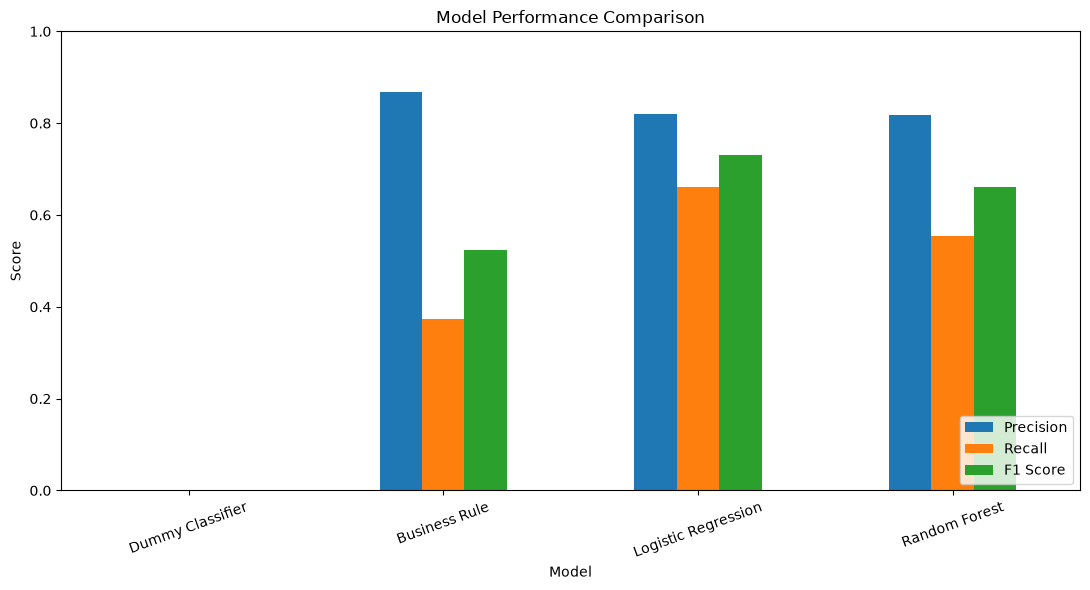

In [12]:
import matplotlib.pyplot as plt

results[["Precision", "Recall", "F1 Score"]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# Stage 4: Baselines and Modelling

Four approaches were evaluated using the validation dataset.

The first approach was a Dummy Classifier, which
predicted the majority class for every student.

The second approach was a business rule that flagged
students who had outstanding tuition fees or were
recorded as debtors.

The third approach was Logistic Regression, a
classification algorithm used to estimate the
probability of student dropout.

The fourth approach was Random Forest, an ensemble
learning algorithm that combines multiple decision
trees.

Both machine learning models used a preprocessing
pipeline containing OneHotEncoder and StandardScaler.

The models were trained using the training subset
and evaluated using the same validation dataset.

The final test dataset was not used during model
selection.

The best-performing model will be selected after
examining the evaluation metrics and conducting
further tuning.


Confusion Matrix:
[[321  33]
 [ 77 150]]


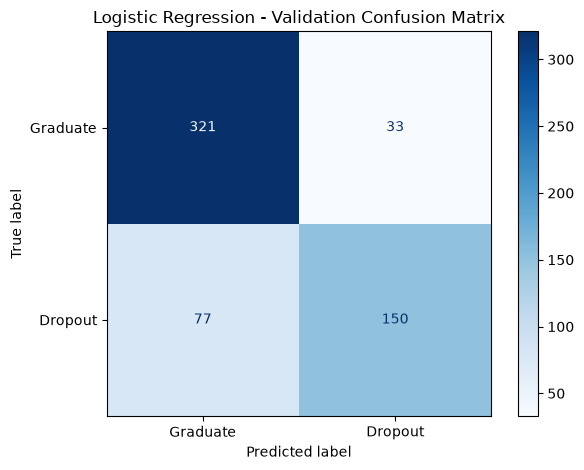

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Predict validation outcomes
y_val_pred = logistic_pipeline.predict(X_val)

# Generate confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Graduate", "Dropout"]
).plot(cmap="Blues")

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

Confusion Matrix:
[[321  33]
 [ 77 150]]


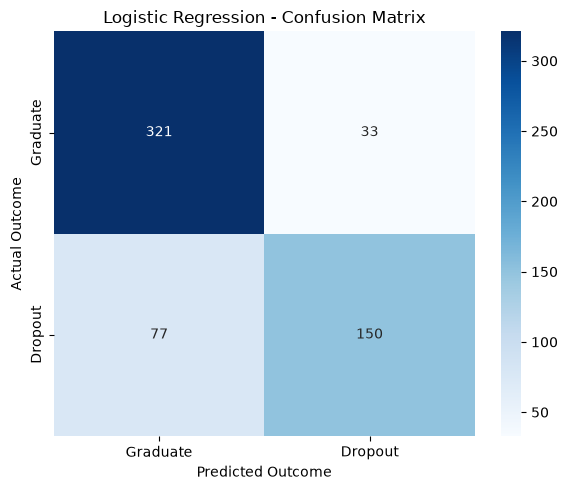

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Get validation predictions
y_val_pred = logistic_pipeline.predict(X_val)

# Create confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

print("Confusion Matrix:")
print(cm)

# Visualise
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Graduate", "Dropout"],
    yticklabels=["Graduate", "Dropout"]
)

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()


In [15]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Graduate", "Dropout"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

    Graduate       0.81      0.91      0.85       354
     Dropout       0.82      0.66      0.73       227

    accuracy                           0.81       581
   macro avg       0.81      0.78      0.79       581
weighted avg       0.81      0.81      0.81       581



In [16]:

# Predict dropout probabilities
y_val_prob = logistic_pipeline.predict_proba(X_val)[:, 1]

probability_results = pd.DataFrame({
    "Actual Outcome": y_val.values,
    "Dropout Probability": y_val_prob,
    "Predicted Outcome": y_val_pred
})

probability_results.head(10)


,Actual Outcome,Dropout Probability,Predicted Outcome
0,0,0.035041,0
1,0,0.232116,0
2,0,0.123122,0
3,0,0.033811,0
4,0,0.012295,0
5,0,0.041971,0
6,0,0.330266,0
7,1,0.996473,1
8,0,0.040794,0
9,0,0.309226,0


In [17]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.30, 0.40, 0.50, 0.60]

threshold_results = []

for threshold in thresholds:

    predictions = (
        y_val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1 Score
0,0.3,0.6545,0.7930,0.7171
1,0.4,0.7376,0.7181,0.7277
2,0.5,0.8197,0.6608,0.7317
3,0.6,0.8684,0.5815,0.6966


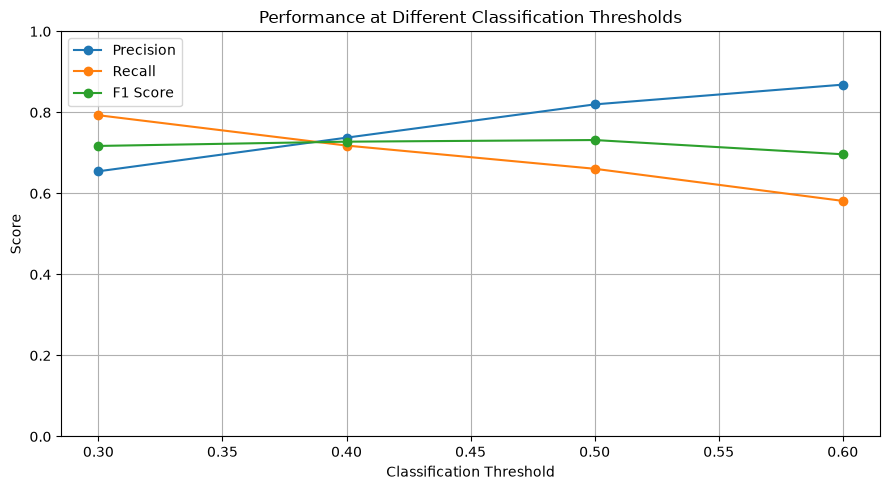

In [18]:

threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Performance at Different Classification Thresholds")
plt.ylabel("Score")
plt.xlabel("Classification Threshold")
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()


In [19]:

# Find incorrect predictions
errors = probability_results[
    probability_results["Actual Outcome"] !=
    probability_results["Predicted Outcome"]
].copy()

# Add error type
errors["Error Type"] = errors.apply(
    lambda row: (
        "False Negative"
        if row["Actual Outcome"] == 1
        else "False Positive"
    ),
    axis=1
)

print("Total incorrect predictions:", len(errors))

display(errors.head(15))


Total incorrect predictions: 110


,Actual Outcome,Dropout Probability,Predicted Outcome,Error Type
20,1,0.226677,0,False Negative
32,0,0.854971,1,False Positive
34,1,0.064861,0,False Negative
39,1,0.214363,0,False Negative
41,0,0.640967,1,False Positive
43,0,0.770517,1,False Positive
51,1,0.087933,0,False Negative
52,0,0.504685,1,False Positive
59,1,0.193090,0,False Negative
68,1,0.433078,0,False Negative


In [20]:

import os

os.makedirs("reports", exist_ok=True)

threshold_df.to_csv(
    "reports/threshold_comparison.csv",
    index=False
)

errors.to_csv(
    "reports/validation_errors.csv",
    index=False
)

print("Evaluation results saved successfully!")


Evaluation results saved successfully!


In [21]:
from sklearn.model_selection import GridSearchCV

logistic_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

logistic_params = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_params,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

logistic_grid.fit(X_train_model, y_train_model)

print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(logistic_grid.best_score_, 4))


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Logistic Regression Parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Best Cross-Validation F1 Score:
0.7174


In [22]:

rf_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__class_weight": [None, "balanced"]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train_model, y_train_model)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(rf_grid.best_score_, 4))


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Random Forest Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}

Best Cross-Validation F1 Score:
0.7115


In [23]:

best_logistic = logistic_grid.best_estimator_
best_rf = rf_grid.best_estimator_

tuned_logistic_results = evaluate_model(
    best_logistic,
    X_val,
    y_val,
    "Tuned Logistic Regression"
)

tuned_rf_results = evaluate_model(
    best_rf,
    X_val,
    y_val,
    "Tuned Random Forest"
)

print("Tuned Logistic Regression:")
print(tuned_logistic_results)

print("\nTuned Random Forest:")
print(tuned_rf_results)


Tuned Logistic Regression:
{'Model': 'Tuned Logistic Regression', 'Accuracy': 0.7848537005163512, 'Precision': 0.7276785714285714, 'Recall': 0.7180616740088106, 'F1 Score': 0.7228381374722838, 'ROC-AUC': 0.8503447074342319, 'PR-AUC': 0.8263040130288568}

Tuned Random Forest:
{'Model': 'Tuned Random Forest', 'Accuracy': 0.7762478485370051, 'Precision': 0.7214611872146118, 'Recall': 0.6960352422907489, 'F1 Score': 0.7085201793721974, 'ROC-AUC': 0.8388337191069962, 'PR-AUC': 0.8167893989187024}


In [24]:

all_results = pd.DataFrame([
    dummy_results,
    rule_results,
    logistic_results,
    random_forest_results,
    tuned_logistic_results,
    tuned_rf_results
])

all_results = all_results.set_index("Model")

display(all_results.round(4))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Dummy Classifier,0.6093,0.0000,0.0000,0.0000,0.5000,0.3907
Business Rule,0.7332,0.8673,0.3744,0.5231,0.6689,0.5692
Logistic Regression,0.8107,0.8197,0.6608,0.7317,0.8529,0.8318
Random Forest,0.7780,0.8182,0.5551,0.6614,0.8376,0.8148
Tuned Logistic Regression,0.7849,0.7277,0.7181,0.7228,0.8503,0.8263
Tuned Random Forest,0.7762,0.7215,0.6960,0.7085,0.8388,0.8168


In [25]:
all_results.to_csv(
    "reports/model_comparison.csv"
)

print("Model comparison saved!")

Model comparison saved!
